# 03 · E3: Faster R-CNN trained on KITTI (RQ2)

**Why a second architecture.** Faster R-CNN is the classic **two-stage** detector: a region proposal network first
suggests candidate boxes, then a second network classifies and refines each one. It is usually more accurate on small
objects than single-stage detectors, but slower. Comparing it with YOLOv8s answers RQ2 (accuracy versus speed).

torchvision's ResNet-50 FPN version, COCO-pretrained, with a new box head for KITTI's 8 classes. Images are used at
torchvision's default size (shorter side 800 px). 10 epochs, batch 4.

**Setup.** Installs the pinned library versions on Kaggle and imports the shared code (`kitti_common.py`, written and
explained in `00_common.ipynb`): data access, the KITTI evaluator, training loops and plots.

In [1]:
SMOKE = False   # True = quick pipeline test (5 % of the data, 2 epochs); the numbers are then meaningless

import os, sys, json, subprocess
from pathlib import Path
os.environ["KITTI_SMOKE"] = "1" if SMOKE else "0"
if Path("/kaggle/input").exists():                     # Kaggle: install the pinned libraries, find the shared code
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.214", "albumentations==2.0.8"],
                   check=True)
    for r, dirs, files in os.walk("/kaggle/input"):
        if "kitti_common.py" in files:
            sys.path.insert(0, r)
            break
        dirs[:] = [d for d in dirs if not d.startswith(("images", "labels", "label_2"))]
from kitti_common import *
seed_everything()
print("Kaggle" if ON_KAGGLE else "local", "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
      "| smoke test" if SMOKE else "")

Kaggle | GPU: Tesla T4 


## Data

In [2]:
tables = prepare_data()

copy images/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy labels/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy images/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy labels/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy images/test:   0%|          | 0/1543 [00:00<?, ?it/s]

copy labels/test:   0%|          | 0/1543 [00:00<?, ?it/s]

data ready in /tmp/kitti: train 4699, val 1239, test 1543


## Training

Each epoch: one pass over the training images, then the **validation loss** (the same losses on the validation
images, without updating the model) and the validation primary metric with our evaluator. The best epoch on
validation is kept.

In [3]:
w, info = train_frcnn("E3", tables, epochs=10, batch=4)
info

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 220MB/s]


epoch 1/10 train:   0%|          | 0/1175 [00:00<?, ?it/s]

/kaggle/input/kitti-v2-00-common/kitti_common.py:629: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


epoch 1/10 val loss:   0%|          | 0/310 [00:00<?, ?it/s]

epoch 1/10 val mAP:   0%|          | 0/155 [00:00<?, ?it/s]

... (34 outputs left out)

epoch 10/10 val loss:   0%|          | 0/310 [00:00<?, ?it/s]

epoch 10/10 val mAP:   0%|          | 0/155 [00:00<?, ?it/s]

epoch 10: train loss 0.164 | val loss 0.520 | val primary 0.779


{'model': 'fasterrcnn_resnet50_fpn (COCO)',
 'imgsz': '800/1333',
 'batch': 4,
 'max_epochs': 10,
 'epochs_run': 10,
 'best_epoch': 2,
 'train_hours': 1.792,
 'settings': '{"optimizer": "SGD", "lr": 0.01, "amp": true}'}

## Training history

Faster R-CNN's loss has four parts: the region proposal network's *objectness* (is there an object here?) and box
loss, and the second stage's *classification* and *box regression*. Blue = training, orange = validation; the
learning rate drops ×10 at 70 % and 90 % of training, which usually shows as a step down in both curves.

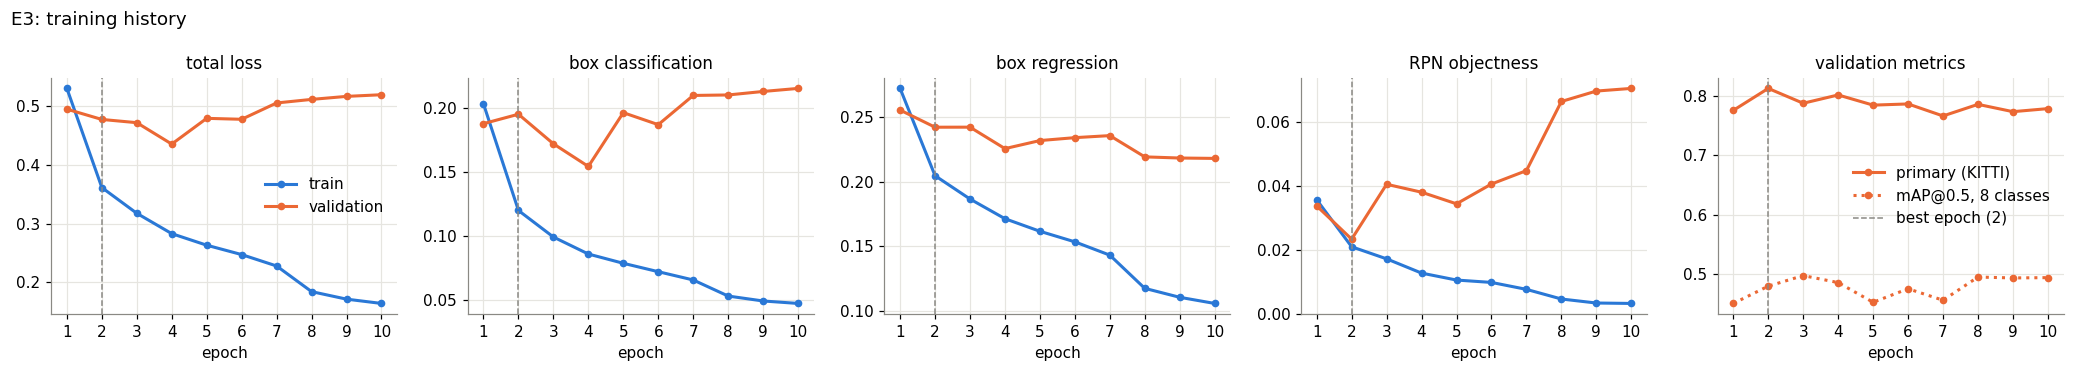

In [4]:
plot_frcnn_history("E3")

## Validation

In [5]:
val, val_table, _ = evaluate_model("E3", "frcnn", w, tables, "val")
headline(validation=val)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 188MB/s]


E3 on val:   0%|          | 0/155 [00:00<?, ?it/s]

,validation
"Primary (Car/Ped/Cyc, Moderate)",0.812
Car,0.971
Pedestrian,0.761
Cyclist,0.704
Easy (3 classes),0.948
Hard (3 classes),0.746
Car AP@0.7,0.933
"mAP@0.5, all 8 classes",0.481
"mAP@0.5:0.95, all 8 classes",0.267


## Test set (once)

The model is now fixed: every choice above was made on validation. It is scored once on the test set, i.e. on drives
it has never seen.

In [6]:
test, test_table, test_preds = evaluate_model("E3", "frcnn", WEIGHTS / "E3.pt", tables, "test", imgsz=640)
headline(validation=val, test=test)

E3 on test:   0%|          | 0/193 [00:00<?, ?it/s]

,validation,test
"Primary (Car/Ped/Cyc, Moderate)",0.812,0.854
Car,0.971,0.968
Pedestrian,0.761,0.814
Cyclist,0.704,0.779
Easy (3 classes),0.948,0.897
Hard (3 classes),0.746,0.819
Car AP@0.7,0.933,0.932
"mAP@0.5, all 8 classes",0.481,0.516
"mAP@0.5:0.95, all 8 classes",0.267,0.304


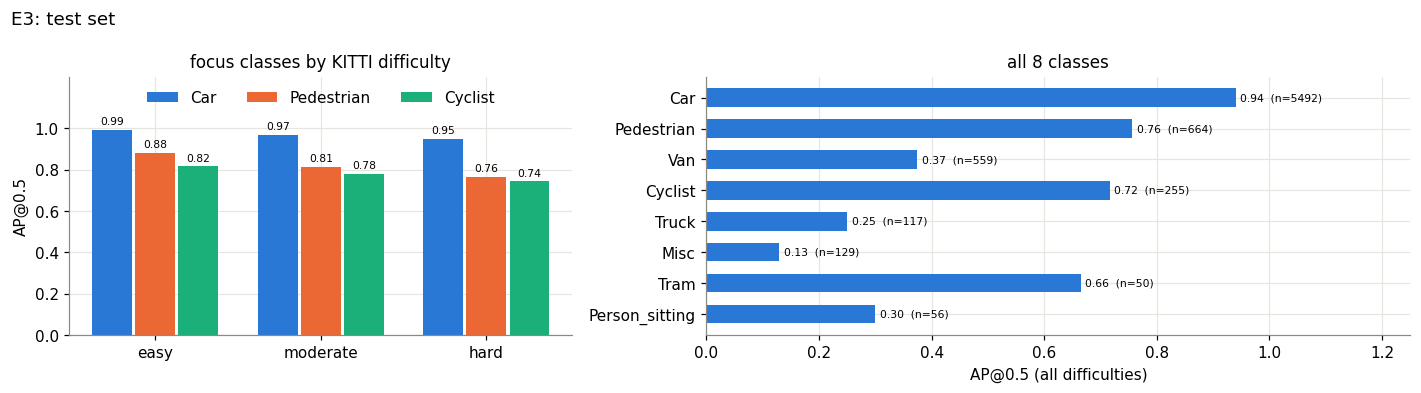

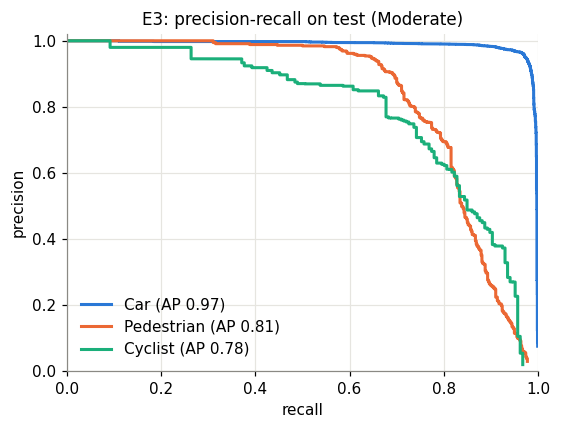

In [7]:
plot_per_class("E3", test_table, "test set")
plot_pr("E3", test_preds, tables, "test")

A few test images (the same ones in every notebook): detections with score ≥ 0.4 against the ground truth.

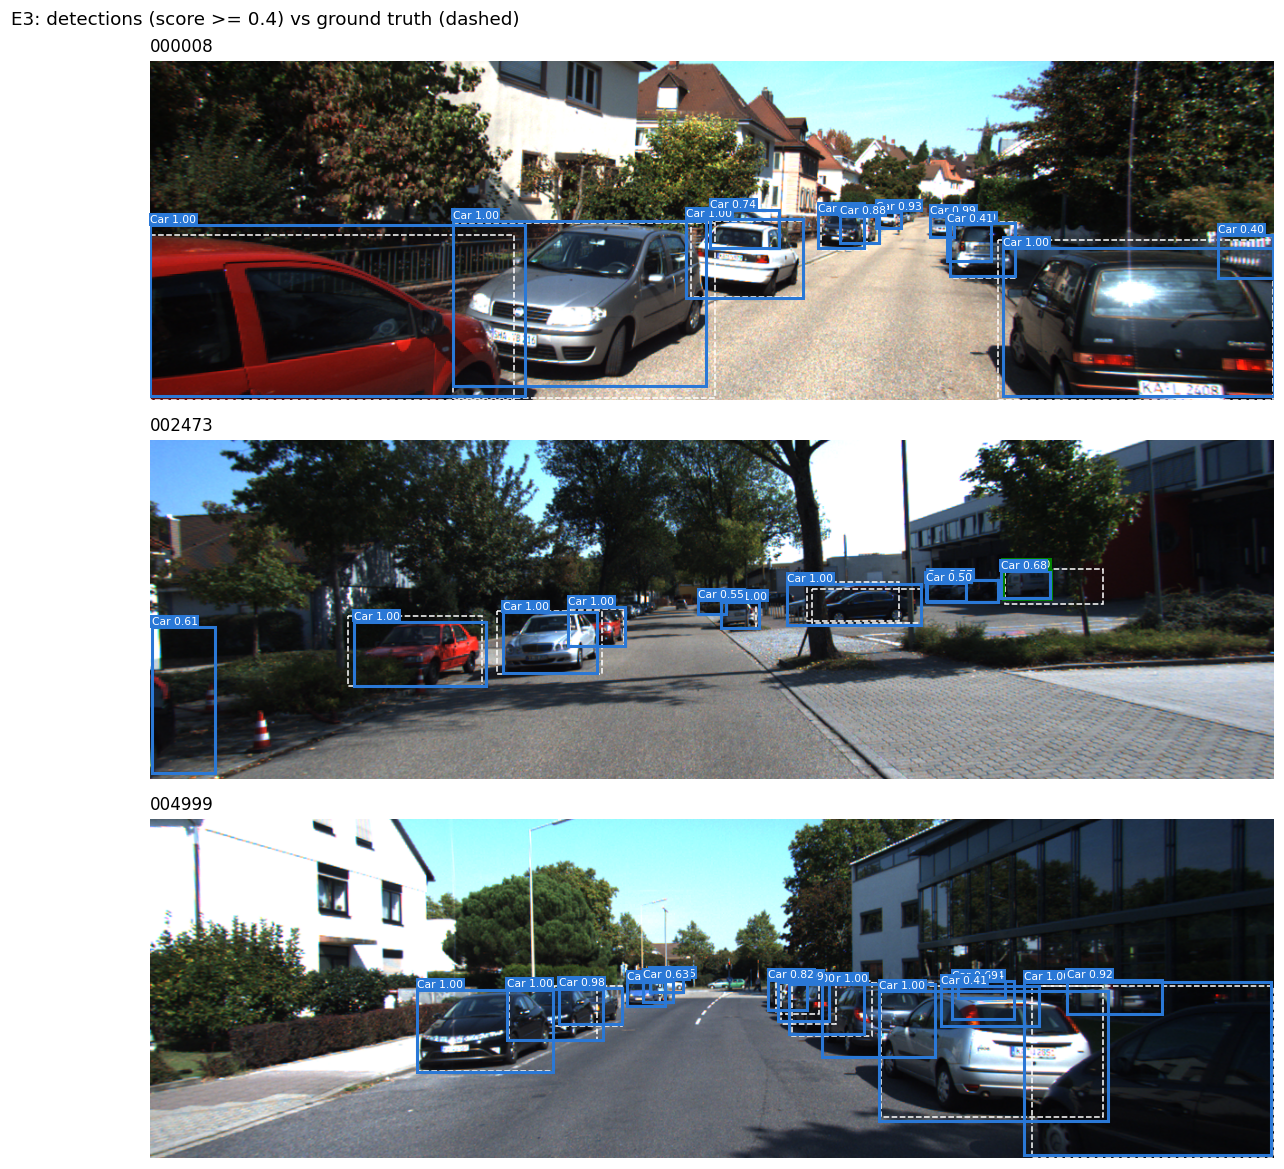

In [8]:
EXAMPLES = split_ids(tables[0], "test")[::max(1, len(split_ids(tables[0], "test")) // 3)][:3]
show_detections("E3", test_preds, tables, EXAMPLES)

## Observations

- **Faster R-CNN is the most accurate model in the project: 0.812 validation, 0.854 test**, against 0.716 for
  YOLOv8s at the same stage (E2) and 0.799 for the tuned final YOLOv8s.
- The difference is mostly **cyclists (0.779 vs 0.441 for E2)** and pedestrians (0.814 vs 0.744). Faster R-CNN works
  on images about twice as large (resized to ~1333 px wide, against 640 px for YOLO) and its second stage re-examines every candidate box,
  which helps small and rare objects. Cars are equal (0.968 vs 0.965).
- **The same overfitting pattern as YOLO:** best epoch **2 of 10**. The training loss falls steadily; the validation
  loss reaches its lowest point at epoch 2–4 and then rises, most clearly in the RPN objectness loss.
- **The price is cost:** 1.8 h of training against 0.2 h for E2. Inference speed on the laptop is measured in
  notebook 08 (E7); that measurement decides whether the accuracy gain is worth it for the app (RQ2).

## Record

The experiment's row of the experiment log (`results/E3/record.json`).

In [9]:
rec = save_record("E3", "Faster R-CNN ResNet-50 FPN fine-tuned on KITTI", "RQ2", val=val, test=test, **info)
pd.Series(rec).to_frame("value")

,value
exp_id,E3
description,Faster R-CNN ResNet-50 FPN fine-tuned on KITTI
research_question,RQ2
model,fasterrcnn_resnet50_fpn (COCO)
imgsz,800/1333
batch,4
max_epochs,10
epochs_run,10
best_epoch,2
train_hours,1.792
